> **Ghi chú (cập nhật sau):** người mới nên đọc `00_hieu_dataset_DAD.ipynb` trước. Một số kết luận ở notebook này đã được cập nhật trong `02_data_mining_cho_monitor.ipynb`:
> - Bộ phát hiện **D3 "biến động"** (mục 8) được thay bằng **D4 "lệch âm ≥ 3/6 chu kỳ"**: 0 báo giả thay vì 9.
> - Con số **1.088** của bài báo đã được xác nhận là 544 PUBLISH + 544 PUBACK (Table 5 của bài báo gấp đôi CSV).
> - Ánh xạ cảm biến theo giá trị (mục 4) được giữ; bài báo tự mâu thuẫn ở điểm này (02, mục 7.3).

# DAD: EDA và thông số thiết kế hệ thống giám sát IoT real-time

**Bộ dữ liệu:** L. Vigoya, D. Fernandez, V. Carneiro, F. Cacheda, *Annotated Dataset for Anomaly Detection in a Data Center with IoT Sensors*, Sensors 2020, 20(13), 3745, doi:[10.3390/s20133745](https://doi.org/10.3390/s20133745). Dữ liệu: [github.com/dad-repository/dad](https://github.com/dad-repository/dad).

**Bối cảnh:** MUGVN Hackathon 2026 (MongoDB × Datadog), đề bài *IoT Real-time Operations*. Hệ thống phải phát hiện, điều tra và xử lý trọn vẹn một sự cố, dùng MongoDB Time Series Collections, aggregation/window functions, `expireAfterSeconds`, và Datadog (dashboard, monitor, logs/APM).

**Notebook này làm gì**
1. Kiểm kê file và đọc trực tiếp PCAP để lấy telemetry (giá trị nhiệt độ nằm trong payload MQTT, không có sẵn trong CSV).
2. Đối chiếu các con số trong bài báo với dữ liệu thật.
3. EDA: cảm biến, nhịp gửi, quan hệ giữa các cảm biến, đặc điểm từng loại bất thường, cách gán nhãn.
4. Thử ba bộ phát hiện đơn giản và đo trên nhãn.
5. Rút ra thông số cụ thể cho pipeline: replay MQTT, schema MongoDB, truy vấn aggregation, metric và monitor Datadog, chính sách khắc phục.

> Mọi con số trong notebook được tính lại từ file gốc khi chạy. Chỗ nào là suy luận hoặc đề xuất thiết kế thì ghi rõ.

## 0. Thiết lập

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from dad_download import ensure_dad
from dad_loader import load_all, DAYS, INROW_IP

RAW = os.path.join("..", "..")   # PCAP + CSV nằm ở gốc repo dad
CACHE = os.path.join("..", "data", "processed")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
DAY_VI = {"mon": "T2 21/10", "tue": "T3 22/10", "wed": "T4 23/10", "thu": "T5 24/10",
          "fri": "T6 25/10", "sat": "T7 26/10", "sun": "CN 27/10"}

## 1. Tải dữ liệu và kiểm kê file

In [2]:
files = ensure_dad(RAW)
inv = pd.DataFrame({"file": files,
                    "KB": [round(os.path.getsize(os.path.join(RAW, f)) / 1024) for f in files]})
inv["loại"] = inv["file"].str.extract(r"\.(\w+)$")[0]
print(inv.groupby("loại")["KB"].agg(["count", "sum"]))
inv

      count   sum
loại             
csv       7  2708
md        1     1
pcap      7  8786
xml       7  6671


,file,KB,loại
0,README.md,1,md
1,capture_1910210000_labels.csv,385,csv
2,capture_1910210000_labels.xml,948,xml
3,capture_1910210000_mon.pcap,1249,pcap
4,capture_1910220000_labels.csv,384,csv
5,capture_1910220000_labels.xml,945,xml
6,capture_1910220000_tue.pcap,1245,pcap
7,capture_1910230000_labels.csv,387,csv
8,capture_1910230000_labels.xml,954,xml
9,capture_1910230000_wed.pcap,1256,pcap


In [3]:
print(open(os.path.join(RAW, "README.md"), encoding="utf-8").read())
print(open(os.path.join(RAW, "capture_1910230000_labels.csv")).read()[:300])

# dad
DATASET for Anomaly Detection in IoT Networks

DAD is a semi-synthetic and labeled dataset consisting of seven days network activity with attacks spread over five days. It has three  different types of anomalies: duplication, interception and modification on the MQTT message. 

The anomaly traffic is made from IP source 10.6.56.41. The attacks has been done in specific days of the week. 
The distribution is as follows:

- Monday 21st: there is no attacks.
- Tuesday 22nd: some packets have been removed, so packets are not labeled as attack.
- Wednesday 23rd: a modification of packets is made between 4h and 6h.
- Thursday 24th: insertion of packets in less than 5 minutes at 3h. 
- Friday 25th: a mix of interception, duplication and modification is done at 6h and between the 14-16h.
- Saturday 26th: a mix of interception, duplication and modification is done at 6h and between the 14-16h.
- Sunday 27th: there is no attacks.

Information & Citation Request:

L. Vigoya, D. Fernandez, V

**Nhận xét**
- Repo có 7 file PCAP theo ngày (mỗi file khoảng 1,3 MB) và 7 cặp nhãn CSV/XML cùng nội dung. Không có file đặc trưng hay file nhiệt độ dựng sẵn.
- CSV nhãn có 6 cột: `frame.number; ip.src; tcp.srcport; mqtt.clientid; mqtt.msgid; label`. Ghép với PCAP theo `(ngày, frame.number)`.
- Repo không có file LICENSE, chỉ yêu cầu trích dẫn bài báo. Vì vậy repo này **không commit dữ liệu**, chỉ commit code tải về.

## 2. Đọc PCAP: định dạng bản tin MQTT

In [4]:
from scapy.all import rdpcap
from scapy.contrib.mqtt import MQTT, MQTTPublish, MQTTConnect
sample = rdpcap(os.path.join(RAW, "capture_1910230000_wed.pcap"), count=120)
shown = 0
for p in sample:
    if p.haslayer(MQTTConnect) and shown < 2:
        print("CONNECT ", p["IP"].src, "clientId =", p[MQTTConnect].clientId); shown += 1
for p in sample:
    if p.haslayer(MQTTPublish):
        m = p[MQTT]; pub = p[MQTTPublish]
        print("PUBLISH ", p["IP"].src, "sport", p["TCP"].sport, "| topic =", pub.topic,
              "| payload =", pub.value, "| QoS =", m.QOS, "| msgid =", pub.msgid)
        break

CONNECT  10.6.56.34 clientId = b'253'
CONNECT  10.6.56.34 clientId = b'251'
PUBLISH  10.6.56.34 sport 40834 | topic = b'IoT' | payload = b'11.06' | QoS = 1 | msgid = 1


In [5]:
packets, pubs = load_all(RAW, CACHE)   # lần đầu mất khoảng 1 phút, sau đó đọc từ cache
print("packets:", packets.shape, " publishes:", pubs.shape)
pubs.head()

packets: (101583, 13)  publishes: (32288, 16)


,day,frame,ts,src,sport,client_id,msgid,topic,value,dup_flag,label,time_utc,time,inrow,sensor,gap_s
0,mon,143,1.571609e+09,10.6.56.41,49134,131,1,IoT,12.12,0,0,2019-10-20 22:00:02.608530998+00:00,2019-10-21 00:00:02.608530998+02:00,13,TFEU,NaN
1,mon,199,1.571609e+09,10.6.56.41,49134,131,2,IoT,12.12,0,0,2019-10-20 22:05:02.709629059+00:00,2019-10-21 00:05:02.709629059+02:00,13,TFEU,300.101098
2,mon,249,1.571609e+09,10.6.56.41,49134,131,3,IoT,12.31,0,0,2019-10-20 22:10:02.811069965+00:00,2019-10-21 00:10:02.811069965+02:00,13,TFEU,300.101441
3,mon,297,1.571610e+09,10.6.56.41,49134,131,4,IoT,12.13,0,0,2019-10-20 22:15:02.912472010+00:00,2019-10-21 00:15:02.912472010+02:00,13,TFEU,300.101402
4,mon,349,1.571610e+09,10.6.56.41,49134,131,5,IoT,12.33,0,0,2019-10-20 22:20:03.013988018+00:00,2019-10-21 00:20:03.013988018+02:00,13,TFEU,300.101516


**Định dạng thật của bản tin** (đọc từ PCAP):
- Mọi cảm biến publish lên **cùng một topic `IoT`**, payload là số dạng text (ví dụ `b'20.00'`), **QoS 1** nên broker trả PUBACK.
- `clientId` chỉ xuất hiện trong gói CONNECT, nên phải ánh xạ `(ip, cổng nguồn)` sang `clientId`. Kết nối TCP có thể kéo từ file ngày trước sang, nên bảng ánh xạ được giữ qua các ngày.
- Một `clientId` có dạng `<InRow><vị trí 1–4>`, ví dụ `131`.

## 3. Đối chiếu số liệu với bài báo

In [6]:
mqtt_types = packets["mqtt_types"].fillna("").str.split(",").explode()
type_name = {"1": "CONNECT", "2": "CONNACK", "3": "PUBLISH", "4": "PUBACK", "14": "DISCONNECT"}
print(mqtt_types[mqtt_types != ""].map(type_name).value_counts())

check = pd.DataFrame([
    ("Tổng số packet", 101583, len(packets)),
    ("Packet TCP", 98142, (packets.proto == "TCP").sum()),
    ("Packet UDP", 3441, (packets.proto == "UDP").sum()),
    ("Frame có MQTT", 64872, (packets.n_mqtt > 0).sum()),
    ("Dòng nhãn = 1 trong CSV", "1.088 (gọi là packet anomaly)", int(packets.label.sum())),
    ("Flow anomaly", 544, "CSV không có flow"),
], columns=["Chỉ số", "Bài báo", "Đo được"])
check

mqtt_types
PUBLISH       32288
PUBACK        32268
CONNECT         112
CONNACK         112
DISCONNECT       92
Name: count, dtype: int64


,Chỉ số,Bài báo,Đo được
0,Tổng số packet,101583,101583
1,Packet TCP,98142,98142
2,Packet UDP,3441,3441
3,Frame có MQTT,64872,64872
4,Dòng nhãn = 1 trong CSV,1.088 (gọi là packet anomaly),544
5,Flow anomaly,544,CSV không có flow


In [7]:
per_day = pd.DataFrame({
    "packet": packets.groupby("day", observed=True).size(),
    "PUBLISH": pubs.groupby("day", observed=True).size(),
    "nhãn=1": packets.groupby("day", observed=True).label.sum().astype(int),
})
per_day.index = [DAY_VI[d] for d in per_day.index]
is_pub = packets.mqtt_types.astype(str).str.split(",").apply(lambda l: "3" in l)
print("Số frame nhãn 1 là bản tin PUBLISH:", int(((packets.label == 1) & is_pub).sum()), "/", int(packets.label.sum()))
per_day

Số frame nhãn 1 là bản tin PUBLISH: 544 / 544


,packet,PUBLISH,nhãn=1
T2 21/10,14431,4608,0
T3 22/10,14398,4568,0
T4 23/10,14524,4608,104
T5 24/10,14538,4608,56
T6 25/10,14544,4624,192
T7 26/10,14630,4648,192
CN 27/10,14518,4624,0


**Kết quả đối chiếu**
- Khớp chính xác: 101.583 packet, 98.142 TCP, 3.441 UDP, 64.872 frame MQTT.
- **CSV chỉ có 544 dòng nhãn 1, không phải 1.088.** Số theo ngày (104, 56, 192, 192) trùng với số *flow* anomaly trong bài báo. Mỗi dòng nhãn 1 là đúng một bản tin PUBLISH (mục 7). Con số 1.088 trong bài báo bằng đúng 2 × 544, nhiều khả năng đã tính cả PUBLISH lẫn PUBACK. Đây là suy luận, bài báo không nói rõ.
- Mỗi ngày bình thường có 4.608 PUBLISH = 16 cảm biến × 288 lần (5 phút/lần). Thứ Ba ít hơn (bị xoá gói), thứ Sáu và thứ Bảy nhiều hơn (gửi dồn).

## 4. Ánh xạ `clientId` sang loại cảm biến

In [8]:
pubs["pos"] = pubs["client_id"].str[2]
m = pubs.groupby(["inrow", "pos"]).value.mean().unstack().round(2)
m.columns = [f"vị trí {c}" for c in m.columns]
m

,vị trí 1,vị trí 2,vị trí 3,vị trí 4
inrow,,,,
13,11.84,15.80,19.92,27.25
15,11.68,15.36,20.00,27.20
23,11.13,14.95,20.00,26.29
25,11.24,15.34,20.01,26.79


Bài báo (Table 1) cho trung bình 14 ngày dữ liệu thật: TAS ≈ 20,0 °C, TAR ≈ 26,3–27,3, TFEU ≈ 11,1–11,9, TFSU ≈ 15,0–15,9. So với bảng trên, ánh xạ **khớp theo giá trị** là:

| Vị trí trong clientId | Loại cảm biến (suy ra từ giá trị) | Ý nghĩa |
|---|---|---|
| 1 | TFEU | nhiệt độ chất lỏng vào |
| 2 | TFSU | nhiệt độ chất lỏng ra |
| 3 | TAS | nhiệt độ khí cấp (lối lạnh) |
| 4 | TAR | nhiệt độ khí hồi (lối nóng) |

> Ánh xạ này **suy ra từ giá trị**, bài báo không công bố bảng clientId. Trung bình từng InRow cũng khớp Table 1 (ví dụ InRow 13: 11,8 / 15,8 / 19,9 / 27,3 so với 11,94 / 15,89 / 20,00 / 27,33).

In [9]:
POS_TO_SENSOR = {"1": "TFEU", "2": "TFSU", "3": "TAS", "4": "TAR"}
pubs["sensor"] = pubs["pos"].map(POS_TO_SENSOR)
SENSOR_VI = {"TFEU": "chất lỏng vào", "TFSU": "chất lỏng ra", "TAS": "khí cấp", "TAR": "khí hồi"}
pubs["slot"] = pubs["time_utc"].dt.floor("5min")
stats = pubs.groupby(["inrow", "sensor"]).value.describe()[["count", "mean", "std", "min", "max"]].round(2)
stats

count   mean   std    min    max
inrow sensor                                   
13    TAR     2021.0  27.25  0.56  24.25  29.40
      TAS     2021.0  19.92  0.56  16.90  22.11
      TFEU    2021.0  11.84  0.59   8.67  14.23
      TFSU    2021.0  15.80  0.58  12.70  18.11
15    TAR     2017.0  27.20  0.33  25.09  29.26
      TAS     2017.0  20.00  0.32  17.92  22.05
      TFEU    2017.0  11.68  0.37   9.49  13.96
      TFSU    2017.0  15.36  0.37  13.15  17.67
23    TAR     2017.0  26.29  0.33  24.16  28.37
      TAS     2017.0  20.00  0.32  17.93  22.07
      TFEU    2017.0  11.13  0.36   8.86  13.40
      TFSU    2017.0  14.95  0.36  12.71  17.21
25    TAR     2017.0  26.79  0.30  24.72  28.88
      TAS     2017.0  20.01  0.30  17.91  22.07
      TFEU    2017.0  11.24  0.34   8.93  13.51
      TFSU    2017.0  15.34  0.34  13.09  17.61

## 5. EDA telemetry

### 5.1 Phân phối nhiệt độ và chuỗi thời gian

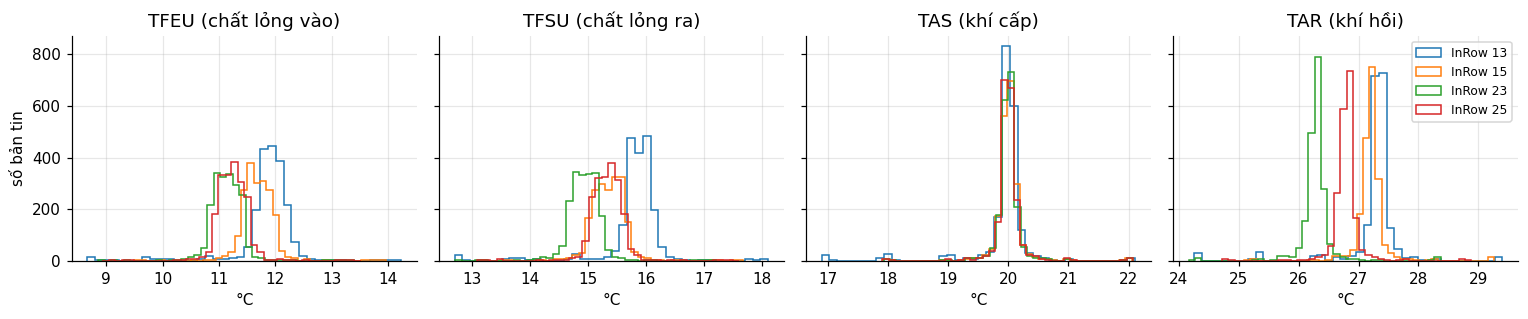

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
order = ["TFEU", "TFSU", "TAS", "TAR"]
for ax, s in zip(axes, order):
    for inrow, g in pubs[pubs.sensor == s].groupby("inrow"):
        ax.hist(g.value, bins=40, histtype="step", label=f"InRow {inrow}")
    ax.set_title(f"{s} ({SENSOR_VI[s]})"); ax.set_xlabel("°C")
axes[0].set_ylabel("số bản tin"); axes[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

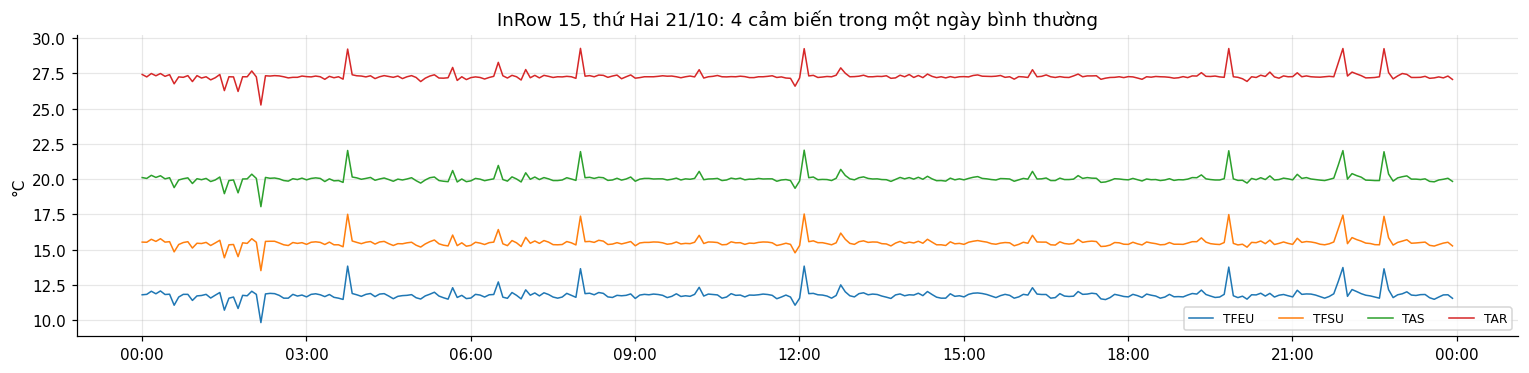

In [11]:
day_df = pubs[(pubs.inrow == 15) & (pubs.day == "mon")]
fig, ax = plt.subplots(figsize=(14, 3.5))
for s in order:
    g = day_df[day_df.sensor == s]
    ax.plot(g.time, g.value, lw=1, label=s)
ax.set_title("InRow 15, thứ Hai 21/10: 4 cảm biến trong một ngày bình thường")
ax.set_ylabel("°C"); ax.legend(ncol=4, fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=day_df.time.dt.tz))
plt.tight_layout(); plt.show()

### 5.2 Quan hệ giữa các cảm biến

In [12]:
wide = pubs.pivot_table(index=["inrow", "slot"], columns="sensor", values="value", aggfunc="first")
diff_corr = wide.loc[15].diff().corr().round(3)
offsets = (wide["TAR"] - wide["TAS"]).groupby(level=0).agg(["mean", "std"]).round(3)
print("Tương quan của bước thay đổi giữa 4 cảm biến InRow 15:"); print(diff_corr)
print("\nĐộ chênh TAR - TAS theo InRow (gần như hằng số):"); print(offsets)

Tương quan của bước thay đổi giữa 4 cảm biến InRow 15:
sensor    TAR    TAS   TFEU   TFSU
sensor                            
TAR     1.000  0.990  0.968  0.982
TAS     0.990  1.000  0.990  0.997
TFEU    0.968  0.990  1.000  0.997
TFSU    0.982  0.997  0.997  1.000

Độ chênh TAR - TAS theo InRow (gần như hằng số):
        mean    std
inrow              
13     7.329  0.065
15     7.197  0.083
23     6.287  0.076
25     6.787  0.077


In [13]:
node = (pubs.assign(c=pubs.value - pubs.groupby("client_id").value.transform("mean"))
            .groupby(["inrow", "slot"]).c.mean().unstack(0))
print("Tương quan giữa các InRow (chuỗi đã bỏ trung bình):"); print(node.corr().round(2))
prof = pubs[pubs.client_id == "153"].assign(tod=lambda d: d.time.dt.hour * 12 + d.time.dt.minute // 5)
prof = prof.pivot_table(index="tod", columns="day", values="value", aggfunc="first", observed=True)
print("\nTương quan giữa các ngày, cùng giờ trong ngày (cảm biến 153):"); print(prof.corr().round(2).iloc[:3])

Tương quan giữa các InRow (chuỗi đã bỏ trung bình):
inrow    13    15    23    25
inrow                        
13     1.00  0.30  0.29  0.08
15     0.30  1.00  0.99  0.12
23     0.29  0.99  1.00  0.10
25     0.08  0.12  0.10  1.00

Tương quan giữa các ngày, cùng giờ trong ngày (cảm biến 153):
day   mon   tue   wed   thu   fri   sat   sun
day                                          
mon  1.00  0.06 -0.03  0.04  0.00  0.02 -0.03
tue  0.06  1.00 -0.01  0.07  0.08 -0.05  0.01
wed -0.03 -0.01  1.00  0.03 -0.04 -0.04 -0.02


**Nhận xét quan trọng cho thiết kế**
- 4 cảm biến của cùng một InRow **di chuyển gần như đồng thời** (tương quan bước thay đổi ≈ 0,97–1,0) và lệch nhau một khoảng gần như cố định. Về thống kê, mỗi InRow giống **một chuỗi chung cộng 4 độ lệch**. Đây là hệ quả của cách sinh dữ liệu bán tổng hợp.
- InRow 15 và 23 gần như trùng nhau (tương quan ≈ 0,99), InRow 13 và 25 khác hẳn.
- **Không có hình mẫu lặp lại theo ngày**: cùng giờ ở các ngày khác nhau tương quan ≈ 0. Nên baseline phải là **cửa sổ trượt gần nhất**, không dùng "cùng giờ hôm qua".
- Chuỗi bình thường có những bước nhảy khoảng 2 °C khá thường xuyên (mục 9.3). Ngưỡng trên từng điểm đơn lẻ sẽ báo động giả nhiều.

### 5.3 Nhịp gửi (cadence)

In [14]:
pubs = pubs.sort_values(["client_id", "ts"]).reset_index(drop=True)
pubs["new_conn"] = pubs.groupby("client_id").sport.shift() != pubs.sport
normal = pubs[pubs.inrow != 13]
print("Khoảng cách giữa 2 bản tin liên tiếp (giây), InRow 15/23/25:")
print(normal.gap_s.describe().round(2))
print("\nCác khoảng < 270 s ở dữ liệu bình thường:")
print(normal[normal.gap_s < 270][["day", "client_id", "time", "gap_s", "new_conn"]].head(10))

Khoảng cách giữa 2 bản tin liên tiếp (giây), InRow 15/23/25:
count    24192.00
mean       299.87
std          6.26
min         29.97
25%        300.10
50%        300.10
75%        300.10
max        300.13
Name: gap_s, dtype: float64

Các khoảng < 270 s ở dữ liệu bình thường:
       day client_id                                time       gap_s  new_conn
9813   sun       151 2019-10-27 00:00:32.210767031+02:00   29.988703      True
11830  sun       152 2019-10-27 00:00:32.214699984+02:00   29.991408      True
13847  sun       153 2019-10-27 00:00:32.205688953+02:00   29.983269      True
15864  sun       154 2019-10-27 00:00:32.218687057+02:00   29.995004      True
17881  sun       231 2019-10-27 00:00:32.186578035+02:00   29.965855      True
19898  sun       232 2019-10-27 00:00:32.195420980+02:00   29.975653      True
21915  sun       233 2019-10-27 00:00:32.186569929+02:00   29.967775      True
23932  sun       234 2019-10-27 00:00:32.191462994+02:00   29.973343      True
24796  wed   

**Nhận xét**
- Nhịp chuẩn là **300,1 giây**, rất đều (phân vị 1% đến 99% đều là 300,1 s).
- Khoảng ngắn bất thường ở dữ liệu bình thường chỉ xảy ra **lúc 00:00, khi cảm biến mở kết nối TCP mới** cho ngày mới. Bộ phát hiện gửi dồn phải bỏ qua bản tin đầu tiên của một kết nối mới (`new_conn`).
- File được cắt theo ngày giờ địa phương Tây Ban Nha. Ngày 27/10/2019 là ngày đổi giờ mùa đông. **Hệ thống nên lưu mọi thời điểm theo UTC**, không dùng giờ địa phương để chia bucket.

## 6. Bản đồ bất thường theo ngày (InRow 13)

In [15]:
r13 = pubs[pubs.inrow == 13]
summary = pd.DataFrame({
    "PUBLISH": r13.groupby("day", observed=True).size(),
    "nhãn=1": r13.groupby("day", observed=True).label.sum().astype(int),
    "khoảng > 450 s": r13[r13.gap_s > 450].groupby("day", observed=True).size(),
    "khoảng < 240 s (cùng kết nối)": r13[(r13.gap_s < 240) & ~r13.new_conn].groupby("day", observed=True).size(),
}).fillna(0).astype(int)
lab_win = r13[r13.label == 1].groupby("day", observed=True).time.agg(["min", "max"])
summary["nhãn từ"] = lab_win["min"].dt.strftime("%H:%M")
summary["nhãn đến"] = lab_win["max"].dt.strftime("%H:%M")
gap_win = r13[r13.gap_s > 450].groupby("day", observed=True).time.agg(["min", "max"])
summary["khoảng hở từ"] = gap_win["min"].dt.strftime("%H:%M")
summary["khoảng hở đến"] = gap_win["max"].dt.strftime("%H:%M")
summary.index = [DAY_VI[d] for d in summary.index]
summary.fillna("")

,PUBLISH,nhãn=1,khoảng > 450 s,khoảng < 240 s (cùng kết nối),nhãn từ,nhãn đến,khoảng hở từ,khoảng hở đến
T2 21/10,1152,0,0,0,,,,
T3 22/10,1112,0,20,0,,,00:30,02:25
T4 23/10,1152,104,0,0,04:10,06:15,,
T5 24/10,1152,56,0,56,03:05,03:22,,
T6 25/10,1168,192,20,96,06:00,16:22,00:00,05:00
T7 26/10,1192,192,24,96,06:00,16:21,03:15,05:00
CN 27/10,1156,0,0,0,,,,


In [16]:
print("Các InRow khác có nhãn hoặc khoảng bất thường không?")
others = pubs[pubs.inrow != 13]
print("nhãn=1:", int(others.label.sum()), "| khoảng > 450 s:", int((others.gap_s > 450).sum()),
      "| khoảng < 240 s cùng kết nối:", int(((others.gap_s < 240) & ~others.new_conn).sum()))
print("Cảm biến bị gắn nhãn:", r13[r13.label == 1].sensor.value_counts().to_dict())

Các InRow khác có nhãn hoặc khoảng bất thường không?
nhãn=1: 0 | khoảng > 450 s: 0 | khoảng < 240 s cùng kết nối: 0
Cảm biến bị gắn nhãn: {'TFEU': 136, 'TFSU': 136, 'TAS': 136, 'TAR': 136}


**Nhận xét**
- Mọi bất thường chỉ nằm ở **InRow 13 (IP 10.6.56.41)**. Các InRow khác hoàn toàn sạch theo cả nhãn lẫn nhịp gửi.
- Mỗi lần bất thường đều tác động **đồng thời cả 4 cảm biến của InRow 13**, đúng với cách tạo: kẻ tấn công can thiệp ở node client. Vì vậy câu chuyện sự cố nên là "node InRow 13 bất thường", không phải "một cảm biến lẻ hỏng".
- Thứ Ba có khoảng hở lớn (mất gói) nhưng **không có nhãn nào**, đúng như README mô tả.
- README ghi thứ Sáu và thứ Bảy "trộn ba loại lúc 6h và 14–16h". Dữ liệu cho thấy phần **mất gói của hai ngày này xảy ra sớm hơn** (khoảng 00:00–05:00 thứ Sáu và 03:15–05:00 thứ Bảy), còn khung 6h và 14–16h là phần có nhãn (gửi dồn và sửa giá trị).

## 7. Từng loại bất thường

### 7.1 Interception (mất gói), thứ Ba 22/10

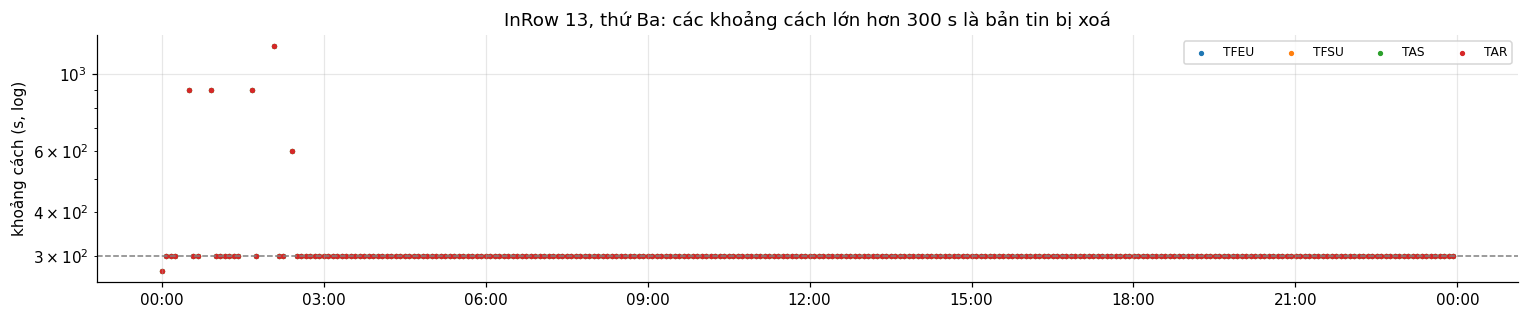

Số khoảng hở: 20 | số bản tin bị mất ước tính: 40
time
00:30    4
00:55    4
01:40    4
02:05    4
02:25    4
dtype: int64


In [17]:
def plot_gaps(day, title):
    d = r13[r13.day == day]
    fig, ax = plt.subplots(figsize=(14, 3))
    for s in order:
        g = d[d.sensor == s]
        ax.scatter(g.time, g.gap_s, s=6, label=s)
    ax.axhline(300, color="gray", ls="--", lw=1); ax.set_yscale("log")
    ax.set_ylabel("khoảng cách (s, log)"); ax.set_title(title); ax.legend(ncol=4, fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=d.time.dt.tz))
    plt.tight_layout(); plt.show()

plot_gaps("tue", "InRow 13, thứ Ba: các khoảng cách lớn hơn 300 s là bản tin bị xoá")
tue = r13[(r13.day == "tue") & (r13.gap_s > 450)]
print("Số khoảng hở:", len(tue), "| số bản tin bị mất ước tính:", int((tue.gap_s / 300.1 - 1).round().sum()))
print(tue.groupby(tue.time.dt.strftime("%H:%M")).size().head(10))

### 7.2 Modification (sửa giá trị), thứ Tư 23/10

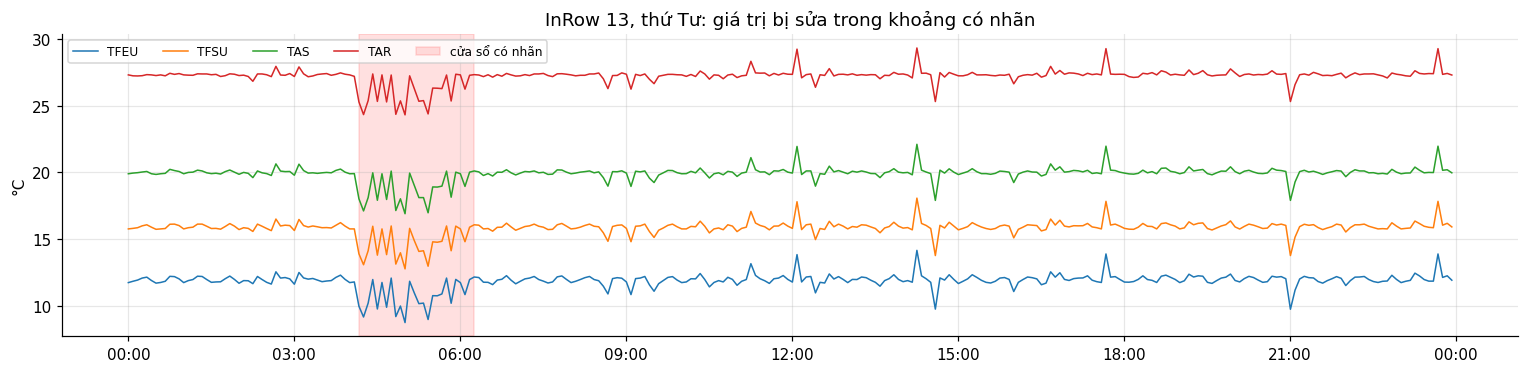

mean                std       
label  bình thường bị sửa bình thường bị sửa
sensor                                      
TAR          27.34  26.06        0.36   1.10
TAS          20.02  18.74        0.38   1.10
TFEU         11.96  10.69        0.41   1.09
TFSU         15.93  14.66        0.39   1.08

In [18]:
w = r13[r13.day == "wed"]
fig, ax = plt.subplots(figsize=(14, 3.5))
for s in order:
    g = w[w.sensor == s]
    ax.plot(g.time, g.value, lw=1, label=s)
lab = w[w.label == 1]
ax.axvspan(lab.time.min(), lab.time.max(), color="red", alpha=0.12, label="cửa sổ có nhãn")
ax.set_title("InRow 13, thứ Tư: giá trị bị sửa trong khoảng có nhãn"); ax.set_ylabel("°C")
ax.legend(ncol=5, fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=w.time.dt.tz))
plt.tight_layout(); plt.show()

cmp = w.groupby(["sensor", w.label.map({0: "bình thường", 1: "bị sửa"})]).value.agg(["mean", "std"]).round(2).unstack()
cmp

In [19]:
wwide = w.pivot_table(index=["slot", "label"], columns="sensor", values="value", aggfunc="first").reset_index()
wwide["TAR-TAS"] = wwide["TAR"] - wwide["TAS"]
print(wwide.groupby("label")["TAR-TAS"].agg(["mean", "std"]).round(3))

        mean    std
label              
0      7.322  0.079
1      7.316  0.080


**Dấu hiệu của modification**
- Trong cửa sổ 04:10–06:15 (26 chu kỳ), cả 4 cảm biến **giảm trung bình khoảng 1,2 °C và dao động mạnh gấp khoảng 3 lần** (độ lệch chuẩn khoảng 1,1 so với 0,4).
- Độ chênh giữa các cảm biến vẫn giữ nguyên, nên **kiểm tra chéo trong cùng InRow không phát hiện được**. Phải nhìn vào **độ biến động theo thời gian**.
- Nhịp gửi không đổi (khoảng cách vẫn 300,1 s), nên bộ phát hiện theo nhịp không thấy loại này.

### 7.3 Duplication (gửi dồn), thứ Năm 24/10

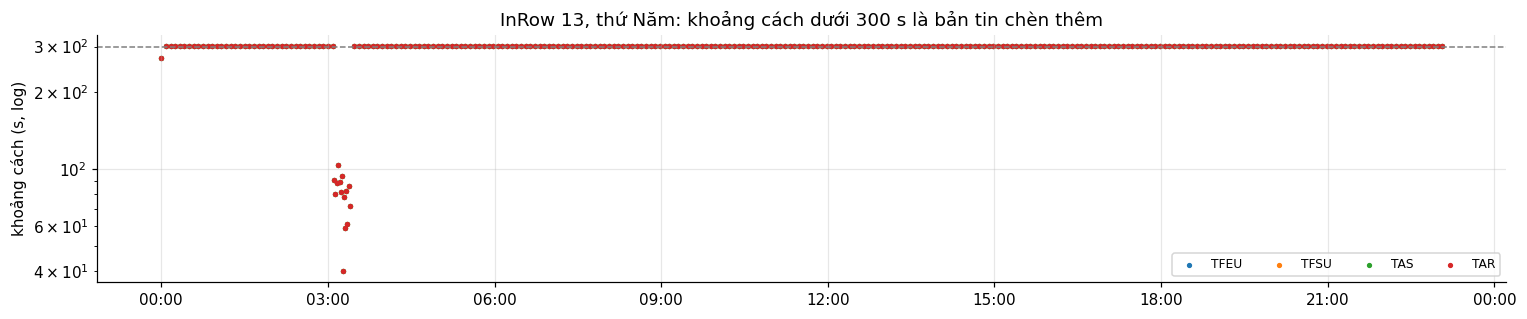

Bản tin có nhãn: 56 | khung giờ: 03:05 - 03:22
Khoảng cách của bản tin có nhãn (s): {'min': 40.1, '50%': 84.1, 'max': 300.1}


In [20]:
plot_gaps("thu", "InRow 13, thứ Năm: khoảng cách dưới 300 s là bản tin chèn thêm")
thu = r13[(r13.day == "thu") & (r13.label == 1)]
print("Bản tin có nhãn:", len(thu), "| khung giờ:", thu.time.min().strftime("%H:%M"), "-", thu.time.max().strftime("%H:%M"))
print("Khoảng cách của bản tin có nhãn (s):", thu.gap_s.describe()[["min", "50%", "max"]].round(1).to_dict())

### 7.4 Thứ Sáu và thứ Bảy: trộn cả ba loại

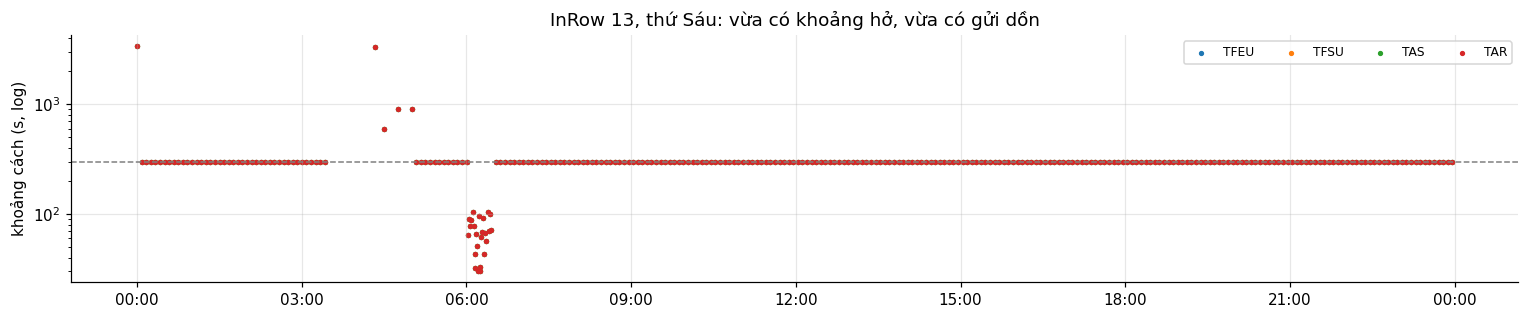

gap_s  < 240 s  240–450 s  > 450 s
label                             
0            4        952       20
1           92        100        0
Nhãn theo giờ: {6: 96, 14: 28, 15: 48, 16: 20}


In [21]:
plot_gaps("fri", "InRow 13, thứ Sáu: vừa có khoảng hở, vừa có gửi dồn")
fri = r13[r13.day == "fri"]
print(pd.crosstab(fri.label, pd.cut(fri.gap_s, [0, 240, 450, 1e9], labels=["< 240 s", "240–450 s", "> 450 s"])))
print("Nhãn theo giờ:", fri[fri.label == 1].groupby(fri.time.dt.hour).size().to_dict())

**Cách gán nhãn (rút ra từ dữ liệu)**
- Nhãn đặt trên **bản tin PUBLISH của InRow 13 trong cửa sổ bị can thiệp**. Ở thứ Sáu, 100 bản tin có nhãn vẫn đến đúng nhịp 300 s: đó là các bản tin bị sửa giá trị hoặc nằm trong cửa sổ trộn.
- Interception không bao giờ có nhãn, vì gói đã bị xoá. Muốn đánh giá phải tự gán bằng quy tắc khoảng hở.
- Để chấm bộ phát hiện, nên dùng **mức sự kiện** (có báo trong cửa sổ không, báo trễ bao lâu) thay vì độ chính xác từng bản tin.

## 8. Thử ba bộ phát hiện đơn giản

Ba quy tắc ứng với ba loại bất thường. Tất cả đều **chỉ dùng dữ liệu quá khứ** (chạy được real-time) và đều viết lại được bằng `$setWindowFields` trong MongoDB (mục 9).

| Bộ phát hiện | Tín hiệu | Ngưỡng đề xuất |
|---|---|---|
| D1 im lặng | khoảng cách từ bản tin trước | > 450 s (1,5 × chu kỳ) |
| D2 gửi dồn | khoảng cách, cùng kết nối TCP | < 240 s (0,8 × chu kỳ) |
| D3 biến động | trung bình \|Δ\| của chuỗi InRow trong 6 chu kỳ | > 1,0 °C trong ≥ 2 chu kỳ liên tiếp |

In [22]:
SILENCE_S, BURST_S, VOL_W, VOL_T, VOL_K = 450, 240, 6, 1.0, 2

pubs["d1_silence"] = pubs.gap_s > SILENCE_S
pubs["d2_burst"] = (pubs.gap_s < BURST_S) & ~pubs.new_conn

nodes = (pubs.assign(c=pubs.value - pubs.groupby("client_id").value.transform("mean"))
             .groupby(["inrow", "slot"])
             .agg(v=("c", "mean"), label=("label", "max"), day=("day", "first"), time=("time", "first"))
             .reset_index().sort_values(["inrow", "slot"]))
nodes["absd"] = nodes.groupby("inrow").v.diff().abs()
nodes["vol"] = nodes.groupby("inrow").absd.transform(lambda s: s.rolling(VOL_W, min_periods=VOL_W).mean())
nodes["over"] = nodes.vol > VOL_T
run = nodes.groupby("inrow").over.transform(lambda s: s.groupby((~s).cumsum()).cumsum())
nodes["d3_vol"] = run >= VOL_K

def events(df, flag, by="inrow", gap="15min"):
    f = df[df[flag]].sort_values([by, "time"])
    if f.empty:
        return pd.DataFrame()
    new = (f.groupby(by).time.diff() > pd.Timedelta(gap)) | (f[by] != f[by].shift())
    f = f.assign(ev=new.cumsum())
    return f.groupby("ev").agg(inrow=(by, "first"), day=("day", "first"),
                               start=("time", "min"), end=("time", "max"), n=(flag, "size")).reset_index(drop=True)

ev1 = events(pubs, "d1_silence"); ev2 = events(pubs, "d2_burst"); ev3 = events(nodes, "d3_vol")
for name, ev in [("D1 im lặng", ev1), ("D2 gửi dồn", ev2), ("D3 biến động", ev3)]:
    print(f"\n{name}: {len(ev)} sự kiện")
    if len(ev):
        print(ev.assign(start=ev.start.dt.strftime("%a %H:%M"), end=ev.end.dt.strftime("%H:%M"))
                .groupby(["inrow", "day"], observed=True).agg(sự_kiện=("n", "size"), lần_đầu=("start", "first")))


D1 im lặng: 14 sự kiện
           sự_kiện    lần_đầu
inrow day                    
13    tue        5  Tue 00:30
      fri        4  Fri 00:00
      sat        5  Sat 03:15

D2 gửi dồn: 3 sự kiện
           sự_kiện    lần_đầu
inrow day                    
13    thu        1  Thu 03:06
      fri        1  Fri 06:01
      sat        1  Sat 06:01

D3 biến động: 16 sự kiện
           sự_kiện    lần_đầu
inrow day                    
13    wed        4  Wed 04:35
      thu        1  Thu 14:28
      fri        2  Fri 14:52
      sat        2  Sat 14:36
15    tue        1  Tue 01:35
      wed        1  Wed 13:35
      thu        1  Thu 15:20
23    tue        1  Tue 01:35
      wed        1  Wed 13:35
      thu        1  Thu 15:20
25    fri        1  Fri 21:40


In [23]:
lab13 = pubs[(pubs.inrow == 13) & (pubs.label == 1)]

def score(ev, name, margin="15min"):
    m = pd.Timedelta(margin)
    hit = ev.apply(lambda r: r.inrow == 13 and ((lab13.time >= r.start - m) & (lab13.time <= r.end + m)).any(), axis=1)
    return ev.assign(detector=name, trùng_nhãn=hit)

scored = pd.concat([score(ev2, "D2 gửi dồn"), score(ev3, "D3 biến động")], ignore_index=True)
tab = scored.groupby("detector").agg(sự_kiện=("n", "size"), trùng_cửa_sổ_nhãn=("trùng_nhãn", "sum"))
tab["báo_giả"] = tab["sự_kiện"] - tab["trùng_cửa_sổ_nhãn"]

def first_delay(ev, day):
    t0 = lab13[lab13.day == day].time.min()
    e = ev[(ev.inrow == 13) & (ev.day == day) & (ev.end >= t0)]
    return round((e.start.min() - t0).total_seconds() / 60, 1) if len(e) else None

tab.loc["D2 gửi dồn", "trễ (phút)"] = first_delay(ev2, "thu")
tab.loc["D3 biến động", "trễ (phút)"] = first_delay(ev3, "wed")
print("Độ trễ: D2 tính trên thứ Năm, D3 tính trên thứ Tư (từ bản tin có nhãn đầu tiên)")
tab

Độ trễ: D2 tính trên thứ Năm, D3 tính trên thứ Tư (từ bản tin có nhãn đầu tiên)


,sự_kiện,trùng_cửa_sổ_nhãn,báo_giả,trễ (phút)
detector,,,,
D2 gửi dồn,3,3,0,1.5
D3 biến động,16,7,9,25.0


In [24]:
fp = scored[~scored.trùng_nhãn]
fp.assign(start=fp.start.dt.strftime("%a %d/%m %H:%M"), end=fp.end.dt.strftime("%H:%M"))[["detector", "inrow", "start", "end", "n"]]

,detector,inrow,start,end,n
6,D3 biến động,13,Wed 23/10 14:40,14:45,2
7,D3 biến động,13,Thu 24/10 14:28,14:48,5
12,D3 biến động,15,Tue 22/10 01:35,01:40,2
13,D3 biến động,15,Wed 23/10 13:35,13:40,2
14,D3 biến động,15,Thu 24/10 15:20,15:40,5
15,D3 biến động,23,Tue 22/10 01:35,01:40,2
16,D3 biến động,23,Wed 23/10 13:35,13:40,2
17,D3 biến động,23,Thu 24/10 15:20,15:40,5
18,D3 biến động,25,Fri 25/10 21:40,21:40,1


In [25]:
normal_nodes = nodes[(nodes.inrow != 13) | nodes.day.isin(["mon", "sun"])]
ok_slots = normal_nodes.vol.notna().sum()
print(f"D3 trên dữ liệu bình thường: {int(normal_nodes.d3_vol.sum())} / {ok_slots} chu kỳ bị báo "
      f"({normal_nodes.d3_vol.mean():.2%}), thành {len(events(normal_nodes, 'd3_vol'))} sự kiện trong 7 ngày × 3 InRow + 2 ngày InRow 13")
wed_lab = nodes[(nodes.inrow == 13) & (nodes.day == "wed") & (nodes.label == 1)]
print(f"D3 trong cửa sổ modification thứ Tư: {wed_lab.d3_vol.mean():.0%} số chu kỳ được báo")
print("D1, D2 trên dữ liệu bình thường:", int(pubs[pubs.inrow != 13].d1_silence.sum()), "và", int(pubs[pubs.inrow != 13].d2_burst.sum()), "báo động")

thu = pubs[(pubs.inrow == 13) & (pubs.day == "thu")]
print("\nD2 trên thứ Năm (chỉ có duplication):")
print(pd.crosstab(thu.label, thu.d2_burst, rownames=["nhãn"], colnames=["D2 báo"]))

D3 trên dữ liệu bình thường: 19 / 6600 chu kỳ bị báo (0.29%), thành 7 sự kiện trong 7 ngày × 3 InRow + 2 ngày InRow 13
D3 trong cửa sổ modification thứ Tư: 58% số chu kỳ được báo
D1, D2 trên dữ liệu bình thường: 0 và 0 báo động

D2 trên thứ Năm (chỉ có duplication):
D2 báo  False  True 
nhãn                
0        1092      4
1           4     52


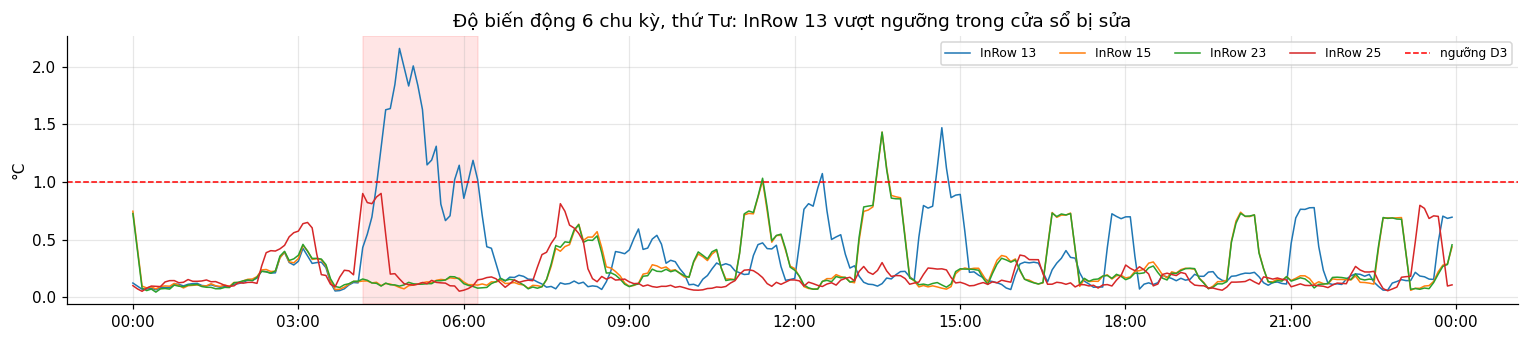

In [26]:
fig, ax = plt.subplots(figsize=(14, 3.2))
for inrow, g in nodes[nodes.day == "wed"].groupby("inrow"):
    ax.plot(g.time, g.vol, lw=1, label=f"InRow {inrow}")
ax.axhline(VOL_T, color="red", ls="--", lw=1, label="ngưỡng D3")
lab = nodes[(nodes.inrow == 13) & (nodes.day == "wed") & (nodes.label == 1)]
ax.axvspan(lab.time.min(), lab.time.max(), color="red", alpha=0.1)
ax.set_title("Độ biến động 6 chu kỳ, thứ Tư: InRow 13 vượt ngưỡng trong cửa sổ bị sửa")
ax.set_ylabel("°C"); ax.legend(ncol=5, fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=lab.time.dt.tz))
plt.tight_layout(); plt.show()

**Kết quả và cách hiểu**
- **D1 và D2 gần như hoàn hảo** trên bộ dữ liệu này: không có báo động nào ở các InRow bình thường, và bắt được mọi khoảng hở và bản tin chèn thêm của InRow 13. Lý do là nhịp gửi bình thường rất đều. Hệ thống thật sẽ có jitter, nên giữ ngưỡng theo bội số chu kỳ thay vì số cứng.
- **D2** bắt duplication thứ Năm trong khoảng 1–2 phút. Lệch đúng 4 bản tin ở biên cửa sổ: bản tin đầu tiên bị chèn vẫn đến đúng nhịp nên chưa có cờ, còn bản tin bình thường đầu tiên sau đợt chèn lại đến sớm nên bị báo.
- **D3 khó hơn nhiều.** Nó bắt được modification thứ Tư sau khoảng 25 phút nhưng chỉ phủ khoảng 58% cửa sổ, và có 9 sự kiện báo giả trong cả tuần (bảng trên), vì chuỗi bình thường cũng có bước nhảy lớn. InRow 15 và 23 báo giả cùng lúc vì hai chuỗi này gần như trùng nhau. Đây là chỗ nên dùng thêm Datadog Anomaly Detection hoặc yêu cầu người vận hành xác nhận trước khi khắc phục.
- Kết quả trên **không phải đánh giá mô hình ML**. Bộ dữ liệu quá nhỏ và chỉ có một nguồn bất thường. Mục đích là chọn ngưỡng có cơ sở cho demo.

## 9. Thông số thiết kế hệ thống giám sát

### 9.1 Lớp thiết bị: replay MQTT
| Thông số | Giá trị đề xuất | Căn cứ |
|---|---|---|
| Số thiết bị | 16 client = 4 InRow × 4 cảm biến | PCAP |
| Chu kỳ gốc | 300 s | mục 5.3 |
| Tốc độ replay | ×60 (5 phút → 5 giây), một ngày chạy trong 24 phút; ×288 cho demo 5 phút/ngày | đề xuất |
| Topic | `dc/{inrow}/{sensor}/temp` (dữ liệu gốc dùng chung topic `IoT`) | đề xuất, để Datadog và MongoDB có tag sẵn |
| Payload | JSON `{"clientId","seq","value","ts"}` với `ts` là UTC đã dịch về hiện tại | mục 5.3 (DST) |
| QoS | 1, giống dữ liệu gốc | mục 2 |
| Topic lệnh | `dc/{inrow}/cmd` cho remediation | đề xuất |
| Bất thường | Phát lại đúng khoảng hở và bản tin chèn thêm từ PCAP; giữ nhãn gốc trong một collection riêng để chấm | mục 6–7 |

### 9.2 MongoDB
**Collections**
| Collection | Loại | Nội dung |
|---|---|---|
| `telemetry` | Time Series, `timeField: ts`, `metaField: meta {site, inrow, sensor, clientId}` | 1 document mỗi bản tin |
| `node_minute` | thường, tạo bằng `$merge` | chuỗi InRow theo chu kỳ, `vol` trượt, cờ D3 |
| `devices` | thường | trạng thái thiết bị, `lastSeen`, `quarantined` |
| `incidents` | thường, TTL 90 ngày tuỳ chọn | sự cố, bằng chứng, hành động, MTTD/MTTR |
| `ground_truth` | thường | nhãn DAD để chấm, không dùng cho phát hiện |

**Thông số**
- `granularity`: `"seconds"` khi replay ×60 (bản tin mỗi 5 s). Nếu chạy đúng thời gian thật (5 phút/bản tin) thì dùng `"minutes"`.
- `expireAfterSeconds`: 7 ngày cho `telemetry` (604800). Một tuần dữ liệu gốc chỉ khoảng 32.000 document nên không lo dung lượng; TTL chủ yếu để chứng minh vòng đời dữ liệu.
- Index phụ: `{ "meta.inrow": 1, "meta.sensor": 1, ts: -1 }`.

In [27]:
CREATE = """
db.createCollection("telemetry", {
  timeseries: { timeField: "ts", metaField: "meta", granularity: "seconds" },
  expireAfterSeconds: 604800
});
db.telemetry.createIndex({ "meta.inrow": 1, "meta.sensor": 1, ts: -1 });
"""

D1_D2 = """
// D1 + D2: khoảng cách giữa hai bản tin liên tiếp của mỗi cảm biến (chu kỳ chuẩn P giây)
db.telemetry.aggregate([
  { $match: { ts: { $gte: new Date(Date.now() - 30*60*1000) } } },
  { $setWindowFields: {
      partitionBy: "$meta.clientId", sortBy: { ts: 1 },
      output: {
        prevTs:   { $shift: { output: "$ts", by: -1 } },
        prevConn: { $shift: { output: "$conn", by: -1 } } } } },
  { $addFields: { gapS: { $dateDiff: { startDate: "$prevTs", endDate: "$ts", unit: "millisecond" } } } },
  { $addFields: { gapS: { $divide: ["$gapS", 1000] } } },
  { $match: { $or: [
      { gapS: { $gt: 1.5 * P } },                                     // D1 im lặng
      { $expr: { $and: [ { $lt: ["$gapS", 0.8 * P] },                 // D2 gửi dồn
                         { $eq: ["$conn", "$prevConn"] } ] } } ] } }
])
"""

D3 = """
// D3: biến động của chuỗi InRow (trung bình |Δ| 6 chu kỳ) > 1.0 °C
db.telemetry.aggregate([
  { $match: { ts: { $gte: new Date(Date.now() - 60*60*1000) } } },
  { $group: { _id: { inrow: "$meta.inrow",
                     slot: { $dateTrunc: { date: "$ts", unit: "second", binSize: P } } },
              v: { $avg: "$centered" } } },          // centered = value - trung bình dài hạn của cảm biến
  { $setWindowFields: {
      partitionBy: "$_id.inrow", sortBy: { "_id.slot": 1 },
      output: { prevV: { $shift: { output: "$v", by: -1 } } } } },
  { $addFields: { absd: { $abs: { $subtract: ["$v", "$prevV"] } } } },
  { $setWindowFields: {
      partitionBy: "$_id.inrow", sortBy: { "_id.slot": 1 },
      output: { vol: { $avg: "$absd", window: { documents: [-5, 0] } } } } },
  { $merge: { into: "node_minute" } }
])
"""
print(CREATE); print(D1_D2); print(D3)


db.createCollection("telemetry", {
  timeseries: { timeField: "ts", metaField: "meta", granularity: "seconds" },
  expireAfterSeconds: 604800
});
db.telemetry.createIndex({ "meta.inrow": 1, "meta.sensor": 1, ts: -1 });


// D1 + D2: khoảng cách giữa hai bản tin liên tiếp của mỗi cảm biến (chu kỳ chuẩn P giây)
db.telemetry.aggregate([
  { $match: { ts: { $gte: new Date(Date.now() - 30*60*1000) } } },
  { $setWindowFields: {
      partitionBy: "$meta.clientId", sortBy: { ts: 1 },
      output: {
        prevTs:   { $shift: { output: "$ts", by: -1 } },
        prevConn: { $shift: { output: "$conn", by: -1 } } } } },
  { $addFields: { gapS: { $dateDiff: { startDate: "$prevTs", endDate: "$ts", unit: "millisecond" } } } },
  { $addFields: { gapS: { $divide: ["$gapS", 1000] } } },
  { $match: { $or: [
      { gapS: { $gt: 1.5 * P } },                                     // D1 im lặng
      { $expr: { $and: [ { $lt: ["$gapS", 0.8 * P] },                 // D2 gửi dồn
                         

> Các truy vấn trên là bản dịch sang MongoDB của logic đã chạy bằng pandas ở mục 8, **chưa được chạy trên MongoDB trong notebook này**. `P` là chu kỳ sau khi replay (300 nếu chạy đúng thời gian, 5 nếu ×60). Trường `conn` (mã kết nối) và `centered` cần được ingest gắn vào mỗi document.

### 9.3 Datadog
**Metric** (gửi qua DogStatsD, tag `inrow`, `sensor`, `client_id`, `env`)
| Metric | Loại | Ý nghĩa |
|---|---|---|
| `dad.temp` | gauge | nhiệt độ từng bản tin |
| `dad.msg.count` | count | số bản tin nhận |
| `dad.msg.gap_seconds` | gauge | khoảng cách tới bản tin trước |
| `dad.node.volatility` | gauge | `vol` của D3 theo InRow |
| `dad.ingest.lag_seconds` | gauge | độ trễ từ `ts` thiết bị tới lúc ghi MongoDB |
| `dad.incident.open` | gauge | số incident đang mở |

**Monitor** (ngưỡng lấy từ mục 8)
| Monitor | Điều kiện | Mức |
|---|---|---|
| Cảm biến im lặng | `max:dad.msg.gap_seconds{*} by {client_id}` > 1,5 × P | cảnh báo |
| Gửi dồn | `sum:dad.msg.count{*} by {client_id}.as_count()` > 2 bản tin mỗi P giây trong 2 chu kỳ | cảnh báo |
| Biến động bất thường | `avg:dad.node.volatility{*} by {inrow}` > 1,0 trong 2 chu kỳ | nghiêm trọng, cần người xác nhận |
| Ingest chậm | `dad.ingest.lag_seconds` > 2 × P | cảnh báo hệ thống |
| Log lỗi khắc phục | log `service:remediator status:error` > 0 | nghiêm trọng |

**Logs và APM**: ingest, detector, remediator bọc bằng `ddtrace`, log JSON có `dd.trace_id`, kèm `inrow`, `client_id`, `incident_id`, `rule`.

### 9.4 Sự cố và khắc phục (theo đúng bản chất DAD)
Mọi bất thường trong DAD xuất phát từ **node InRow 13 (10.6.56.41)** và tác động cả 4 cảm biến. Chính sách nên ở **mức node**:

| Phát hiện | Kết luận | Hành động tự động | Cần người duyệt |
|---|---|---|---|
| D1 trên nhiều cảm biến cùng InRow | node mất kết nối hoặc gói bị chặn | gửi `reconnect` tới `dc/13/cmd`, đánh dấu dữ liệu thiếu, nội suy có gắn cờ | nếu kéo dài > 3 chu kỳ |
| D2 | node gửi lặp hoặc bị chèn bản tin | lọc trùng ở ingest, giới hạn tốc độ client, `restore-interval` | không |
| D3 | dữ liệu của node không đáng tin (bị sửa) | gắn `quality=suspect`, loại khỏi điều khiển làm mát, chuyển sang giá trị của node dự phòng | **có**, vì D3 có báo động giả |

Xác nhận đã khắc phục: 3 chu kỳ liên tiếp không còn cờ nào ở InRow đó, rồi đóng incident và ghi MTTD/MTTR.

### 9.5 Kịch bản demo đề xuất
- **Sự cố chính:** modification thứ Tư 23/10, 04:10–06:15 (26 chu kỳ, cả 4 cảm biến InRow 13). Nén ×60 còn khoảng 2 phút. Cho thấy D3 báo, người vận hành duyệt, cách ly dữ liệu, rồi phục hồi.
- **Sự cố phụ:** duplication thứ Năm 03:05–03:22 (56 bản tin chèn thêm), phát hiện tức thì bằng D2, khắc phục tự động.

## 10. Hạn chế và khai báo

- Dữ liệu là **bán tổng hợp**: giá trị nhiệt độ sinh bằng mô hình STL từ 14 ngày đo thật, traffic tạo trong môi trường ảo. Quan hệ vật lý (tải máy chủ, làm mát) không có trong dữ liệu.
- Ánh xạ vị trí trong `clientId` sang loại cảm biến được **suy ra từ giá trị** (mục 4).
- Chỉ có một nguồn bất thường (InRow 13) và 7 ngày dữ liệu. Các ngưỡng ở mục 8 phù hợp để demo, không phải để khẳng định hiệu năng tổng quát.
- Interception không có nhãn gốc. Mọi đánh giá cho loại này dựa trên quy tắc khoảng hở.
- Repo gốc không có file LICENSE. Khi nộp bài cần trích dẫn bài báo và khai báo DAD là dataset bên ngoài.

**Trích dẫn:** L. Vigoya, D. Fernandez, V. Carneiro, F. Cacheda, "Annotated Dataset for Anomaly Detection in a Data Center with IoT Sensors", *Sensors* 2020, 20(13), 3745. doi:10.3390/s20133745.